# 03 · 可视化与结论建议 —— 让数字开口说话

**项目**：英国在线零售商经营诊断分析

> **可视化设计原则**（选图逻辑，面试常问"为什么用这张图"）：
> - 时间趋势 → **柱线组合图**（GMV 量级用柱、订单数趋势用线）
> - 构成占比 → **饼图 / 堆叠柱**
> - 排名比较 → **横向条形图**（类目名长，横向可读性好）
> - 两维密度（星期×小时、群×月份）→ **热力图**
> - 集中度 → **帕累托曲线**（累计占比）
>
> 每张图遵循同一叙事格式：**图表 → 数据发现 → 业务解读**。

所有图表自动导出至 `charts/` 目录（README 直接引用）。

## 0. 环境与数据加载

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

warnings.filterwarnings('ignore')
# 注意：sns.set_theme 会重置字体，必须在其后再设中文字体
sns.set_theme(style='whitegrid')
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

BLUE, ORANGE, GRAY = '#2E5A88', '#E8804C', '#9AA5B1'

sales = pd.read_csv('../data/cleaned/sales_clean.csv', parse_dates=['InvoiceDate'])
returns = pd.read_csv('../data/cleaned/returns_clean.csv', parse_dates=['InvoiceDate'])
# 退货口径拆分（见 02 · Q7 的发现）：只保留真实商品退货，剔除平台费冲销/手工调整等非商品行
special_codes = {'POST', 'DOT', 'M', 'D', 'CRUK', 'C2', 'PADS', 'S',
                 'BANK CHARGES', 'ADJUST', 'AMAZONFEE', 'GIFT'}
_sc = returns['StockCode'].astype(str).str.upper()
returns = returns[(~_sc.isin(special_codes)) & (~_sc.str.lower().str.startswith('gift'))].copy()
monthly = pd.read_csv('../data/cleaned/analysis_monthly.csv')
rfm = pd.read_csv('../data/cleaned/analysis_rfm.csv')
retention = pd.read_csv('../data/cleaned/analysis_retention.csv', index_col=0)
country = pd.read_csv('../data/cleaned/analysis_country.csv')
hw = pd.read_csv('../data/cleaned/analysis_hour_week.csv', index_col=0)
prod = pd.read_csv('../data/cleaned/analysis_products.csv')
ret_month = pd.read_csv('../data/cleaned/analysis_return_month.csv', index_col=0)
print('数据加载完成，开始绘图')

数据加载完成，开始绘图


## 图 1 · 月度 GMV 与订单量：生意的"心电图"

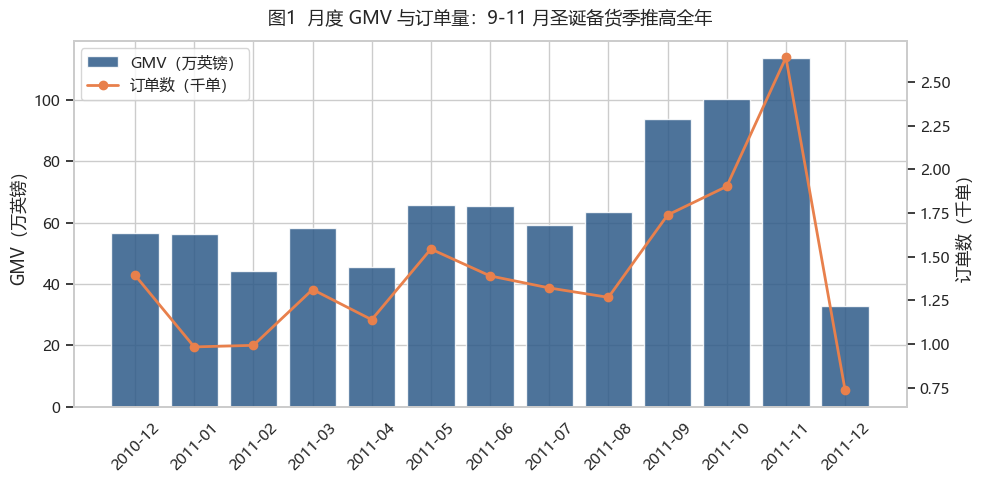

In [2]:
fig, ax1 = plt.subplots(figsize=(10, 5))
x = monthly['InvoiceMonth']
ax1.bar(x, monthly['GMV'] / 10000, color=BLUE, alpha=0.85, label='GMV（万英镑）')
ax1.set_ylabel('GMV（万英镑）')
ax1.tick_params(axis='x', rotation=45)

ax2 = ax1.twinx()
ax2.plot(x, monthly['订单数'] / 1000, color=ORANGE, marker='o', lw=2, label='订单数（千单）')
ax2.set_ylabel('订单数（千单）')
ax2.grid(False)

ax1.set_title('图1  月度 GMV 与订单量：9-11 月圣诞备货季推高全年', fontsize=13, pad=12)
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc='upper left')
fig.tight_layout()
fig.savefig('../charts/fig01_monthly_trend.png', dpi=140, bbox_inches='tight')
plt.show()

**数据发现**：GMV 与订单量同向波动；2011 年 2-4 月为低谷，9-11 月受圣诞备货拉动冲至全年高峰；年末 12 月（仅 1-8 日）按口径截断。

**业务解读**：这是一门**强季节性**的礼品批发生意。资源排布（库存资金、临时人力、营销预算）应按"Q4 旺季"设计；2-4 月淡季可安排清库存与老客召回，用低成本活动填谷。

## 图 2 · 客单价 AOV 与客户均消费 ARPPU：增长动能体检

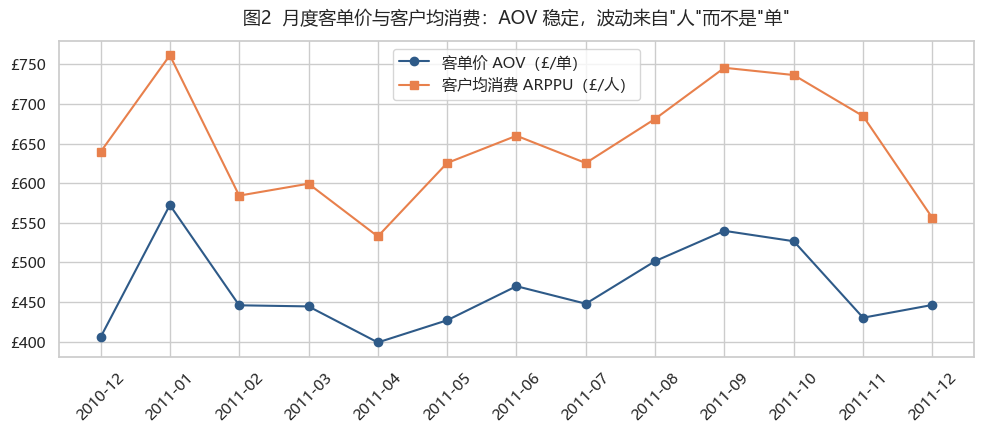

In [3]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(monthly['InvoiceMonth'], monthly['客单价AOV'], color=BLUE, marker='o', label='客单价 AOV（£/单）')
ax.plot(monthly['InvoiceMonth'], monthly['客户均消费ARPPU'], color=ORANGE, marker='s', label='客户均消费 ARPPU（£/人）')
ax.set_title('图2  月度客单价与客户均消费：AOV 稳定，波动来自"人"而不是"单"', fontsize=13, pad=12)
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('£{x:,.0f}'))
ax.tick_params(axis='x', rotation=45)
ax.legend()
fig.tight_layout()
fig.savefig('../charts/fig02_aov_arppu.png', dpi=140, bbox_inches='tight')
plt.show()

**数据发现**：AOV 全年稳定在 £470~530 窄幅区间，ARPPU 随月度 GMV 同步波动。

**业务解读**：GMV 涨跌**不是客户买得更贵**，而是**来得人多了/少了**。提升 GMV 的杠杆在"客户数 × 留存 × 频次"，不在提价——这直接引出 RFM 分层（图 4）与留存诊断（图 5）。

## 图 3 · 市场结构：英国主场与海外增长带

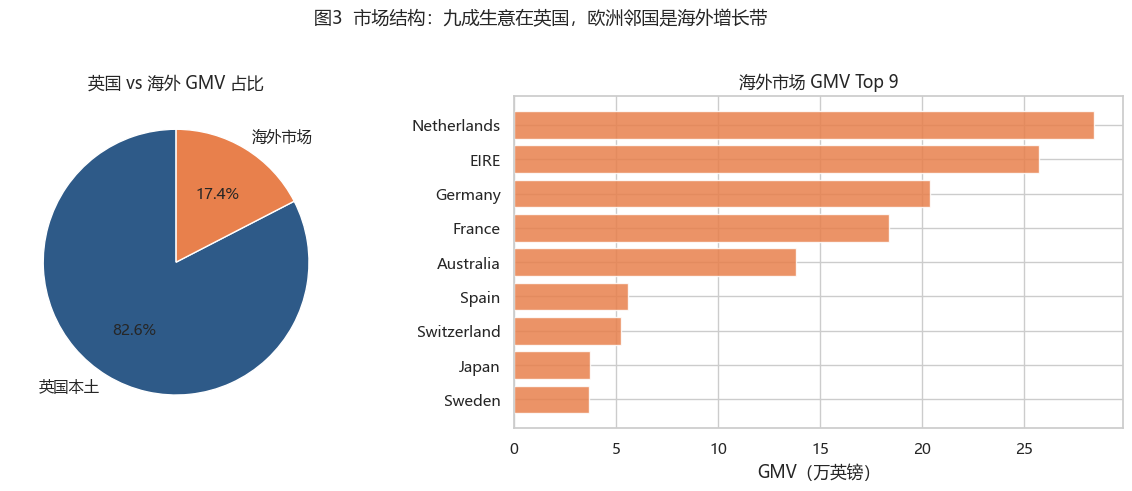

In [4]:
uk_share = country.loc[country['Country'] == 'United Kingdom', 'GMV'].sum()
overseas_share = country['GMV'].sum() - uk_share

fig, (axl, axr) = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={'width_ratios': [1, 1.4]})
axl.pie([uk_share, overseas_share], labels=['英国本土', '海外市场'],
        colors=[BLUE, ORANGE], autopct='%.1f%%', startangle=90,
        textprops={'fontsize': 11})
axl.set_title('英国 vs 海外 GMV 占比', fontsize=12)

top9 = country[country['Country'] != 'United Kingdom'].head(9).iloc[::-1]
axr.barh(top9['Country'], top9['GMV'] / 10000, color=ORANGE, alpha=0.85)
axr.set_xlabel('GMV（万英镑）')
axr.set_title('海外市场 GMV Top 9', fontsize=12)
fig.suptitle('图3  市场结构：九成生意在英国，欧洲邻国是海外增长带', fontsize=13, y=1.02)
fig.tight_layout()
fig.savefig('../charts/fig03_country.png', dpi=140, bbox_inches='tight')
plt.show()

**数据发现**：英国本土贡献 82.6% GMV；海外头部是荷兰（9 个客户贡献 £28.4 万）、爱尔兰（3 个客户 £25.7 万）、德国（93 个客户 £20.4 万）、法国（87 个客户 £18.4 万）。

**业务解读**：本土是基本盘。海外呈两种结构：**荷兰/爱尔兰是"巨鲸型"市场**（极少数大批发客，单客价值 £3~9 万），必须点对点维护、防止单点流失；**德国/法国是"分散型"市场**（客户数多），适合做本地化增长（本地退货地址、多币种报价），是更稳的增量来源。

## 图 4 · RFM 分层：谁是金主，谁在流失？

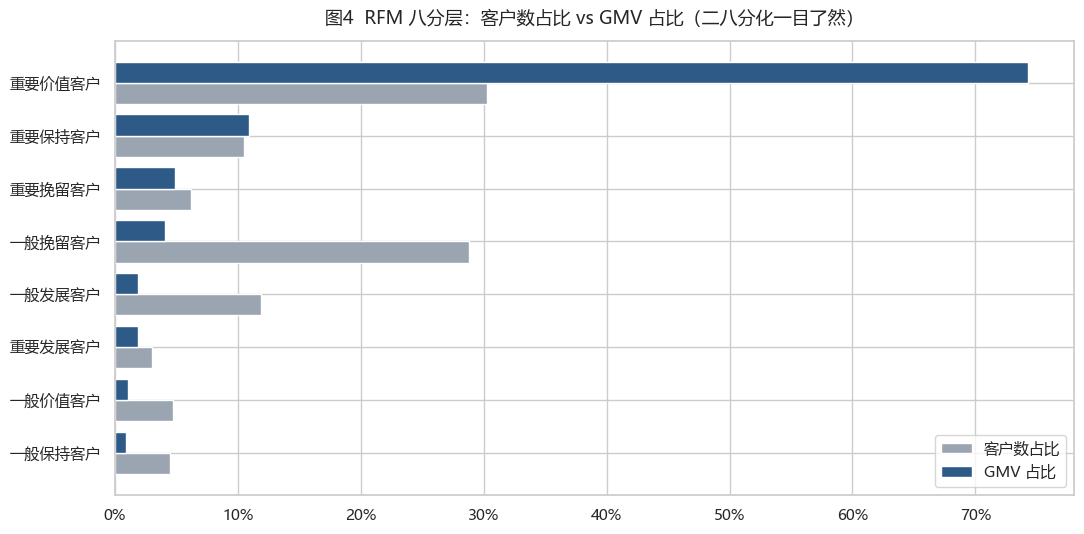

,客户数,GMV,客户数占比,GMV占比
客户分层,,,,
重要价值客户,1311,"6,355,077.63",0.30,0.74
重要保持客户,454,"935,181.11",0.10,0.11
重要挽留客户,268,"419,338.32",0.06,0.05
一般挽留客户,1249,"350,724.78",0.29,0.04
一般发展客户,517,"159,982.21",0.12,0.02
重要发展客户,133,"159,167.96",0.03,0.02
一般价值客户,206,"93,359.52",0.05,0.01
一般保持客户,195,"80,225.45",0.05,0.01


In [5]:
seg = (rfm.groupby('客户分层')
       .agg(客户数=('M', 'size'), GMV=('M', 'sum'))
       .sort_values('GMV', ascending=False))
seg['客户数占比'] = seg['客户数'] / seg['客户数'].sum()
seg['GMV占比'] = seg['GMV'] / seg['GMV'].sum()

y = np.arange(len(seg))
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.barh(y + 0.2, seg['客户数占比'], height=0.4, color=GRAY, label='客户数占比')
ax.barh(y - 0.2, seg['GMV占比'], height=0.4, color=BLUE, label='GMV 占比')
ax.set_yticks(y, seg.index)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.invert_yaxis()
ax.set_title('图4  RFM 八分层：客户数占比 vs GMV 占比（二八分化一目了然）', fontsize=13, pad=12)
ax.legend()
fig.tight_layout()
fig.savefig('../charts/fig04_rfm_segments.png', dpi=140, bbox_inches='tight')
plt.show()
seg

**数据发现**："重要价值客户"以 **30% 的人数贡献 74% 的 GMV**；人数占 29% 的"一般挽留客户"只贡献 4%——批发生意的强二八分化。

**业务解读**（分层运营策略，面试重点）：
- **重要价值客户**（1,311 人）：VIP 专属客服 + 提前发售权，目标是"留住"；
- **重要挽留客户**（268 人，买得多但最近沉默）：**召回优先级最高**——大额满减 + 专属邮箱触达；
- **重要发展客户**（133 人，最近活跃但频次低）：组合装/满额包邮拉升频次；
- **一般挽留客户**（1,249 人）：低成本的自动化邮件触达即可，不烧预算。

## 图 5 · 同期群留存：新客下个月还在吗？

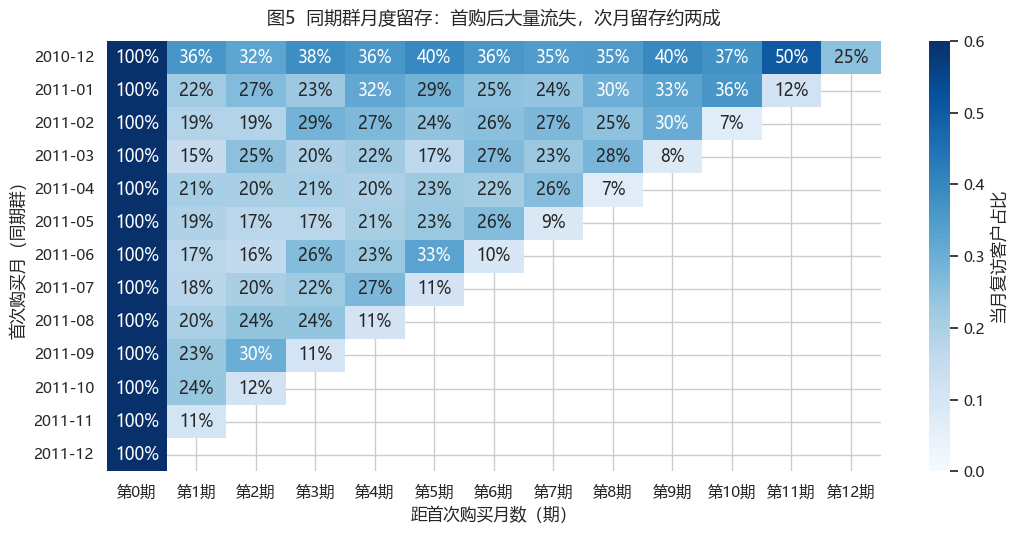

In [6]:
fig, ax = plt.subplots(figsize=(11, 5.5))
sns.heatmap(retention, annot=True, fmt='.0%', cmap='Blues', vmin=0, vmax=0.6,
            cbar_kws={'label': '当月复访客户占比'}, ax=ax)
ax.set_xlabel('距首次购买月数（期）')
ax.set_ylabel('首次购买月（同期群）')
ax.set_title('图5  同期群月度留存：首购后大量流失，次月留存约两成', fontsize=13, pad=12)
ax.set_xticklabels([f'第{int(float(c.get_text()))}期' for c in ax.get_xticklabels()])
fig.tight_layout()
fig.savefig('../charts/fig05_cohort_retention.png', dpi=140, bbox_inches='tight')
plt.show()

**数据发现**：第一列 100%，第二列（次月）骤降至约两成，之后缓慢衰减；各月份同期群形态相似，说明是**常态问题而非某月事故**。

**业务解读**：获客成本花在了"只买一次的人"身上。修复漏水口的关键动作在**首购后 7~30 天**：包裹卡 + 满减券（第二次下单立减）、新品邮件流、忠诚度积分。若把次月留存从两成提升到三成，相当于**零获客成本多出 50% 的复购收入池**。

## 图 6 · 畅销商品 Top 10：生意靠哪些单品撑着？

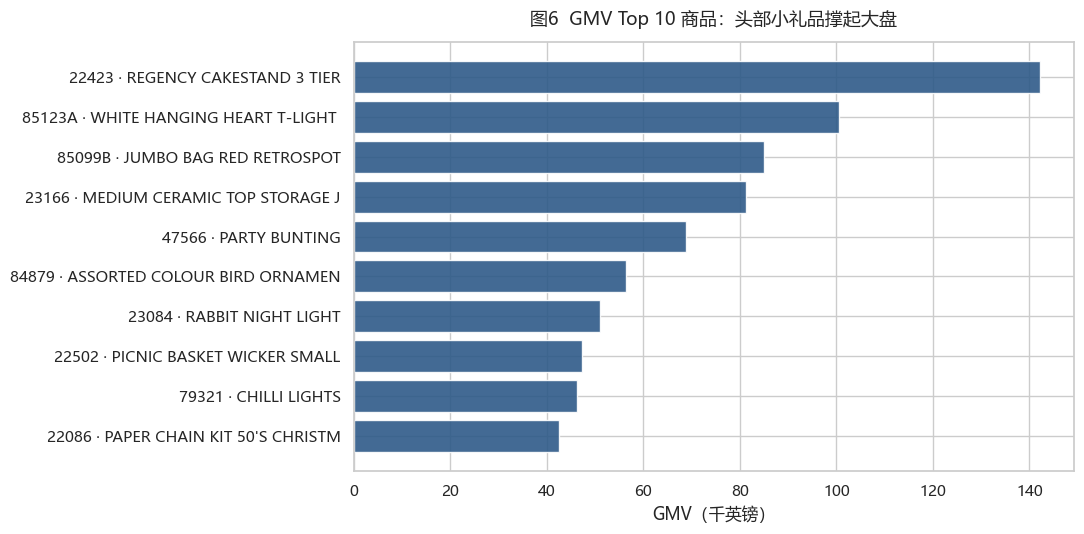

In [7]:
top10 = prod.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 5.5))
names = [f'{c} · {str(d)[:28]}' for c, d in zip(top10['StockCode'], top10['商品名'])]
ax.barh(names, top10['GMV'] / 1000, color=BLUE, alpha=0.9)
ax.set_xlabel('GMV（千英镑）')
ax.set_title('图6  GMV Top 10 商品：头部小礼品撑起大盘', fontsize=13, pad=12)
fig.tight_layout()
fig.savefig('../charts/fig06_top_products.png', dpi=140, bbox_inches='tight')
plt.show()

**数据发现**：Top10 以手工风小礼品（挂饰、灯座、收纳罐等）为主，头部商品单价多在 £3~12，GMV 靠走量。

**业务解读**：头部商品是现金流担当——**安全库存、备选供应商、缺货预警**都要向 Top10 倾斜；同时它们是天然的"引流品"，适合放进广告素材与edm 首屏。

## 图 7 · 帕累托曲线：SKU 集中度体检

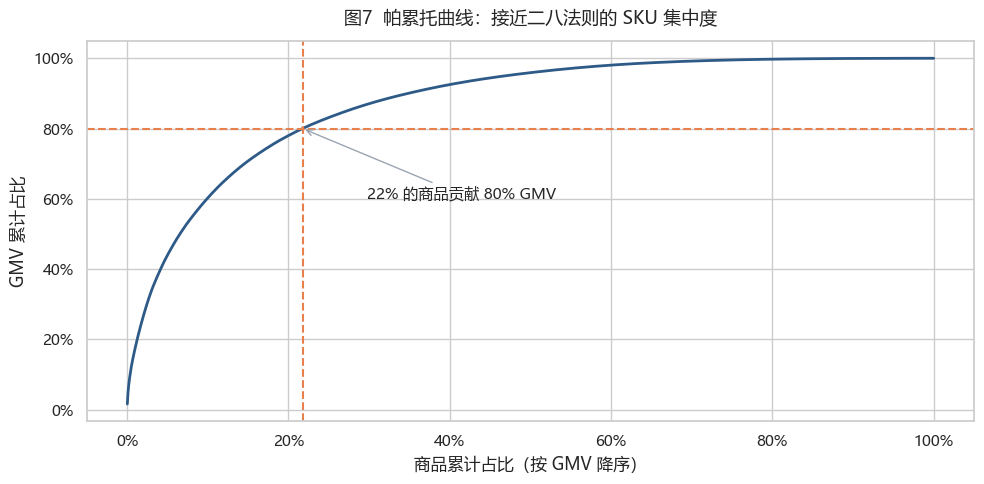

In [8]:
fig, ax = plt.subplots(figsize=(10, 5))
n = len(prod)
xs = np.arange(1, n + 1) / n
ax.plot(xs, prod['累计GMV占比'], color=BLUE, lw=2)
ax.axhline(0.8, color=ORANGE, ls='--', lw=1.5)
n80 = int((prod['累计GMV占比'] < 0.8).sum()) + 1
ax.axvline(n80 / n, color=ORANGE, ls='--', lw=1.5)
ax.annotate(f'{n80 / n:.0%} 的商品贡献 80% GMV', xy=(n80 / n, 0.8),
            xytext=(n80 / n + 0.08, 0.6), fontsize=11,
            arrowprops=dict(arrowstyle='->', color=GRAY))
ax.set_xlabel('商品累计占比（按 GMV 降序）')
ax.set_ylabel('GMV 累计占比')
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_title('图7  帕累托曲线：接近二八法则的 SKU 集中度', fontsize=13, pad=12)
fig.tight_layout()
fig.savefig('../charts/fig07_pareto.png', dpi=140, bbox_inches='tight')
plt.show()

**数据发现**：约两成商品贡献八成 GMV，帕累托法则近似成立。

**业务解读**：SKU 管理抓两头——头部做**深度**（库存与陈列资源倾斜），长尾做**减法**（年动销个位数且无引流价值的 SKU 逐步清退），释放资金与仓储成本。

## 图 8 · 星期 × 小时：黄金营业窗口

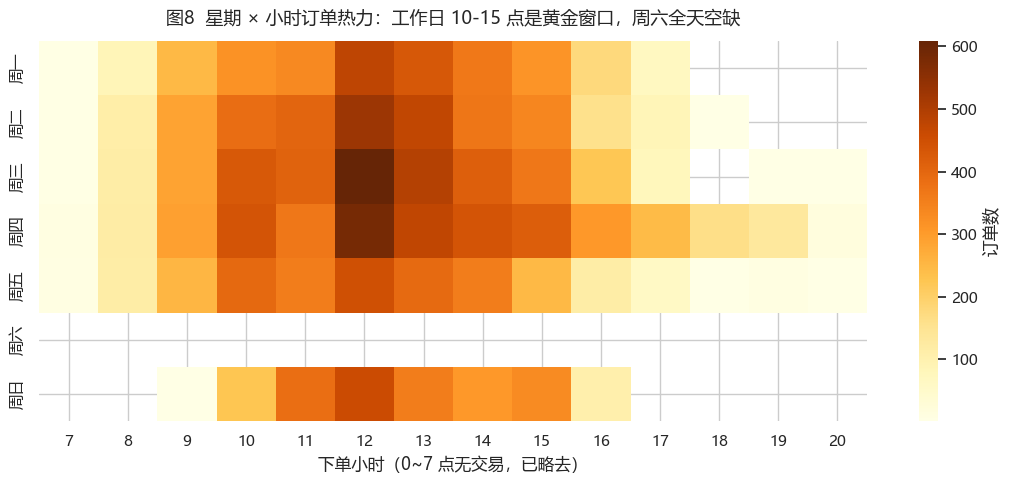

In [9]:
fig, ax = plt.subplots(figsize=(11, 5))
plot_data = hw.copy()
plot_data.index = [i for i in plot_data.index]
sns.heatmap(plot_data, cmap='YlOrBr', annot=False,
            cbar_kws={'label': '订单数'}, ax=ax)
ax.set_xlabel('下单小时（0~7 点无交易，已略去）')
ax.set_ylabel('')
ax.set_title('图8  星期 × 小时订单热力：工作日 10-15 点是黄金窗口，周六全天空缺', fontsize=13, pad=12)
fig.tight_layout()
fig.savefig('../charts/fig08_hour_weekday.png', dpi=140, bbox_inches='tight')
plt.show()

**数据发现**：订单集中在工作日 10:00-15:00；周六全天空缺（批发客户周六不采购），周日仅凌晨有零星交易。

**业务解读**：这是**B2B 生意的时间指纹**。营销推送定在工作日**上午 9:30-11:00**（采购员到岗后的黄金时段）；客服与仓配排班对齐工作日；周末投放预算砍掉或转投自动化邮件。

## 图 9 · 新客 vs 老客：增长靠拉新还是靠复购？

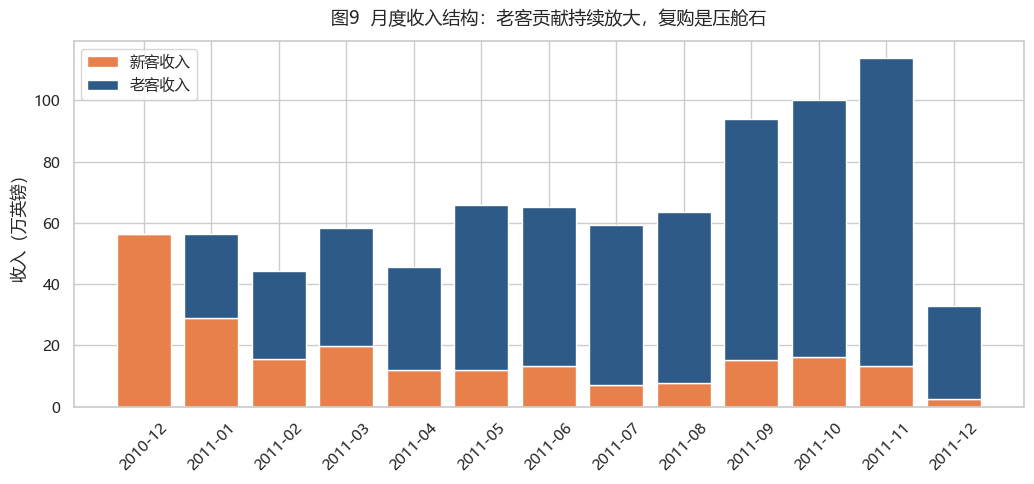

In [10]:
first_month = sales.groupby('CustomerID')['InvoiceMonth'].min().rename('首次月')
sc = sales.merge(first_month, on='CustomerID')
sc['客户类型'] = np.where(sc['InvoiceMonth'] == sc['首次月'], '新客', '老客')
rev_type = sc.pivot_table(index='InvoiceMonth', columns='客户类型', values='Revenue', aggfunc='sum').fillna(0)

fig, ax = plt.subplots(figsize=(10.5, 5))
ax.bar(rev_type.index, rev_type['新客'] / 10000, color=ORANGE, label='新客收入')
ax.bar(rev_type.index, rev_type['老客'] / 10000,
       bottom=rev_type['新客'] / 10000, color=BLUE, label='老客收入')
ax.set_ylabel('收入（万英镑）')
ax.set_title('图9  月度收入结构：老客贡献持续放大，复购是压舱石', fontsize=13, pad=12)
ax.tick_params(axis='x', rotation=45)
ax.legend()
fig.tight_layout()
fig.savefig('../charts/fig09_new_vs_old.png', dpi=140, bbox_inches='tight')
plt.show()

**数据发现**：随时间推移，老客（首购月早于当月）收入占比整体走高，旺季仍以老客备货为主动能。

**业务解读**：生意已经从"拉新驱动"过渡到"复购驱动"。资源分配应向**老客经营**（分层运营、专属优惠）倾斜，而不是一味买量拉新——拉新获来的客若不承接（见图 5 低留存），等于白花获客成本。

## 图 10 · 月度退货率：漏水口在扩大吗？

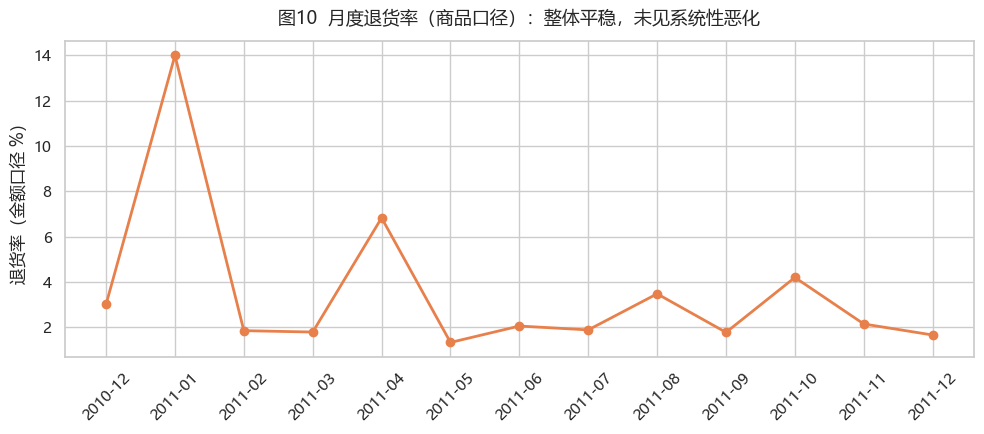

In [11]:
ret_rate = ret_month['ReturnAmount'] / (ret_month['ReturnAmount'] +
           monthly.set_index('InvoiceMonth')['GMV'])
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(ret_rate.index, ret_rate.values * 100, color=ORANGE, marker='o', lw=2)
ax.set_ylabel('退货率（金额口径 %）')
ax.set_title('图10  月度退货率（商品口径）：整体平稳，未见系统性恶化', fontsize=13, pad=12)
ax.tick_params(axis='x', rotation=45)
fig.tight_layout()
fig.savefig('../charts/fig10_return_rate.png', dpi=140, bbox_inches='tight')
plt.show()

**数据发现**：商品口径的月度退货率多数月份在 1%~4% 平稳波动；**2011 年 1 月出现 14% 的一次性冲高**（当月商品退货 £9.2 万，占全年商品退货近三成），此后回落。

**业务解读**：1 月冲高与**圣诞礼品退货潮**高度吻合——节日送出的礼品在节后被退回。治理方向：① 旺季（Q4）销售的商品提前做包装与质检加固；② 对"节日礼品类目"放宽预期但设退货预警线；③ 其余月份平稳说明不存在系统性质量问题，无需全面收紧退货政策（那会误伤正常批发客户体验）。

## 图 11 · 退货金额 Top 10 商品：黑名单清单

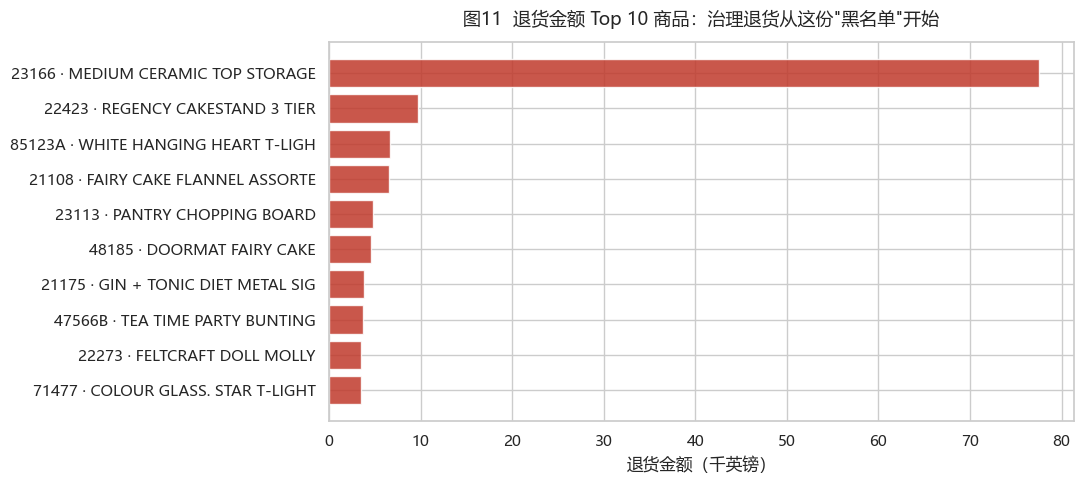

In [12]:
returns['ReturnAmount'] = -returns['Quantity'] * returns['UnitPrice']
name_map = sales.groupby('StockCode')['Description'].agg(lambda x: x.mode().iat[0] if len(x.mode()) else '')
ret_top = returns.groupby('StockCode')['ReturnAmount'].sum().nlargest(10).iloc[::-1]
labels = [f'{c} · {str(name_map.get(c, ""))[:26]}' for c in ret_top.index]

fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(labels, ret_top.values / 1000, color='#C0392B', alpha=0.85)
ax.set_xlabel('退货金额（千英镑）')
ax.set_title('图11  退货金额 Top 10 商品：治理退货从这份"黑名单"开始', fontsize=13, pad=12)
fig.tight_layout()
fig.savefig('../charts/fig11_top_returns.png', dpi=140, bbox_inches='tight')
plt.show()

**数据发现**：退货金额集中于少数商品，以**陶瓷/玻璃等易碎品**与高单价商品为主。

**业务解读**：① 易碎品升级包装与入库质检，从源头降低破损退货；② 对高频退货的海外大单客户建立信用审核；③ 黑名单商品在商品详情页补充尺寸/材质实拍图，减少"货不对板"退货。

## 交互式图表（加分项）

> matplotlib 出的是静态图，给业务方演示时用 pyecharts 生成交互图表（悬停看数、缩放），HTML 文件存放在 `charts/interactive/`，浏览器打开即用。

In [13]:
# 交互式月度趋势（pyecharts 输出 HTML，可放进 README / 汇报 PPT）
try:
    from pyecharts.charts import Bar, Line
    from pyecharts import options as opts
    from pyecharts.globals import CurrentConfig
    import os
    os.makedirs('../charts/interactive', exist_ok=True)

    x = monthly['InvoiceMonth'].tolist()
    bar = (Bar()
           .add_xaxis(x)
           .add_yaxis('GMV(英镑)', [round(v, 2) for v in monthly['GMV']])
           .extend_axis(yaxis=opts.AxisOpts(name='订单数', position='right'))
           .set_global_opts(title_opts=opts.TitleOpts(title='月度 GMV 与订单量（交互版）')))
    line = (Line()
            .add_xaxis(x)
            .add_yaxis('订单数', [int(v) for v in monthly['订单数']], yaxis_index=1))
    bar.overlap(line).render('../charts/interactive/monthly_trend.html')
    print('已生成 charts/interactive/monthly_trend.html')
except Exception as e:
    print('pyecharts 生成跳过:', e)

已生成 charts/interactive/monthly_trend.html


## 业务结论与落地建议

> 每条建议都遵循 **数据发现 → 业务归因 → 落地动作 → 预期指标** 的链条，这是分析报告与"数据观后感"的区别。

### 结论一：增长动能已切换到"复购"，但留存是最大漏水口
- **发现**：AOV 全年稳定（图 2），老客收入占比走高（图 9），同期群次月留存仅约两成（图 5）。
- **归因**：首购之后没有任何承接动作，客户"买完即走"。
- **动作**：搭建"首购后 7 天/30 天"自动化触达（包裹卡+满减券+新品邮件），重点人群用 RFM 名单圈选。
- **预期指标**：次月留存从 ~20% 提升至 ~30%，GMV 增量几乎零获客成本。

### 结论二：资源应向"高价值少数"倾斜
- **发现**：RFM 八分层呈二八分化（图 4）；帕累托曲线显示约两成商品贡献八成 GMV（图 7）。
- **归因**：无差异化的"一刀切"运营，让高价值客户无尊享感、低价值客户占用成本。
- **动作**：重要价值客户 VIP 服务；重要挽留客户定向召回；头部商品安全库存与备选供应商；长尾 SKU 清退。
- **预期指标**：重要挽留客户召回率、头部商品缺货率下降、SKU 数量瘦身后的资金占用下降。

### 结论三：欧洲邻国是低风险增量市场
- **发现**：海外 GMV 约一成且集中在爱尔兰/法国/德国/荷兰（图 3）。
- **归因**：地缘与语言便利使欧洲市场天然易渗透，但服务本地化不足可能压制转化。
- **动作**：欧洲重点市场本地化退货地址、多币种报价、物流时效承诺；海外大单客户建立信用审核。
- **预期指标**：欧洲四国 GMV 占比与海外订单转化率。

### 结论四：营销与运营排期对齐"黄金窗口"
- **发现**：订单集中于工作日 10-15 点，周六停业（图 8）。
- **归因**：B2B 客户在上班时间采购，周末触达基本无效。
- **动作**：EDM/推送定在工作日上午；客服仓配按工作日排班；周末预算转投自动化。
- **预期指标**：推送打开率/下单转化率提升，营销费用利用率提升。

### 结论五：退货治理聚焦"商品黑名单"，财务冲销单独管理
- **发现**：流水口径退货率约 8%，但拆分后过半是亚马逊平台费冲销与手工调整；真实商品退货率约 3~4%，集中于陶瓷储物罐等易碎大件（图 10、11）。
- **归因**：易碎品包装/质检不足导致商品退货；财务冲销与商品退货混在同一口径，会误导质量看板。
- **动作**：易碎品包装升级、质检前置、详情页信息补全、高频退货客户信用审核；平台费冲销单列财务台账。
- **预期指标**：黑名单商品退货率下降，商品口径退货率再降一个台阶。

## 局限性与下一步（数据边界意识，面试加分项）

1. **无浏览行为数据**：数据只有成交，没有 PV/加购，做不了转化漏斗——若补充埋点数据，可分析"浏览→加购→下单"漏斗定位流失环节；
2. **无成本数据**：只有收入没有毛利，"商品贡献"按 GMV 排序可能高估低毛利品——下一步接入采购成本做毛利口径复算；
3. **仅 13 个月**：季节性只有一轮样本，同比分析不可靠——积累第二年后做 YoY 与季节性建模；
4. **客户 ID 缺失 25%**：无法归属的批发展客未纳入客户分析，实际"无主客户"价值可能被低估——建议从 CRM/物流单号侧做二次归属。